## Lab 2: дополнительные задания

Часть 4 - распознавание активности по сигналам смартфона, часть 5 - классификация пород собак.

### Part 4. HAR classification with raw data

Нужно определить один из шести видов активности по девяти сигналам смартфона. Для этого используется сверточная сеть Conv1d.

In [1]:
from pathlib import Path
from copy import deepcopy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(4)

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
print('Устройство:', device, '| PyTorch:', torch.__version__)

def loader(x, y, batch_size=256, shuffle=False, seed=SEED):
    return DataLoader(TensorDataset(x, y), batch_size=batch_size, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(seed), num_workers=0)

@torch.no_grad()
def evaluate(model, batches):
    model.eval()
    total_loss, correct, count = 0.0, 0, 0
    for x, y in batches:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += nn.functional.cross_entropy(logits, y, reduction='sum').item()
        correct += (logits.argmax(1) == y).sum().item()
        count += len(y)
    return {'loss': total_loss / count, 'accuracy': correct / count}

def fit(model, train_batches, train_eval_batches, val_batches, epochs, lr=1e-3,
        weight_decay=0.0, select_best=True):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, epochs, eta_min=lr * 0.05)
    history, best_state, best_loss, best_epoch = [], None, float('inf'), 0
    for epoch in range(1, epochs + 1):
        model.train()
        for x, y in train_batches:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = nn.functional.cross_entropy(model(x), y)
            loss.backward()
            optimizer.step()
        tr, va = evaluate(model, train_eval_batches), evaluate(model, val_batches)
        history.append({'epoch': epoch, 'train_loss': tr['loss'], 'val_loss': va['loss'],
                        'train_accuracy': tr['accuracy'], 'val_accuracy': va['accuracy']})
        if va['loss'] < best_loss:
            best_loss, best_epoch = va['loss'], epoch
            best_state = deepcopy(model.state_dict())
        scheduler.step()
        if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
            print(f"Эпоха {epoch:3d}: train acc={tr['accuracy']:.4f}, val acc={va['accuracy']:.4f}, "
                  f"train loss={tr['loss']:.4f}, val loss={va['loss']:.4f}", flush=True)
    if select_best:
        model.load_state_dict(best_state)
    return pd.DataFrame(history), best_epoch

def plot_histories(histories, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for name, history in histories.items():
        for ax, metric in zip(axes, ['loss', 'accuracy']):
            line, = ax.plot(history.epoch, history['train_' + metric], label=name + ': train')
            ax.plot(history.epoch, history['val_' + metric], '--', color=line.get_color(),
                    label=name + ': validation')
            ax.set(xlabel='Эпоха', ylabel=metric)
            ax.grid(alpha=0.3)
            ax.legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

import zipfile
from urllib.request import urlretrieve

DATA = Path('data')
DATA.mkdir(exist_ok=True)

def download_archive(url, path, destination):
    if not path.exists():
        urlretrieve(url, path)
    with zipfile.ZipFile(path) as archive:
        archive.extractall(destination)

HAR = DATA / 'har' / 'UCI HAR Dataset'
if not HAR.exists():
    download_archive('https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip',
                     DATA / 'har.zip', DATA / 'har')
    # внутри архива лежит ещё один zip с данными
    download_archive('', DATA / 'har' / 'UCI HAR Dataset.zip', DATA / 'har')

Устройство: cpu | PyTorch: 2.15.0+cpu


In [2]:
plt.rcParams.update({'font.size': 10})

Данные: [UCI HAR](https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones). В train 7 352 окна, в test 2 947, в каждом окне 128 отсчётов по 9 каналам. Validation отделяется по людям: окна одного человека сильно перекрываются, и если разделить их случайно, оценка будет завышена.

### PCA по готовым признакам

PCA здесь только для картинки. Сеть обучается на исходных сигналах, а не на 561 готовом признаке.

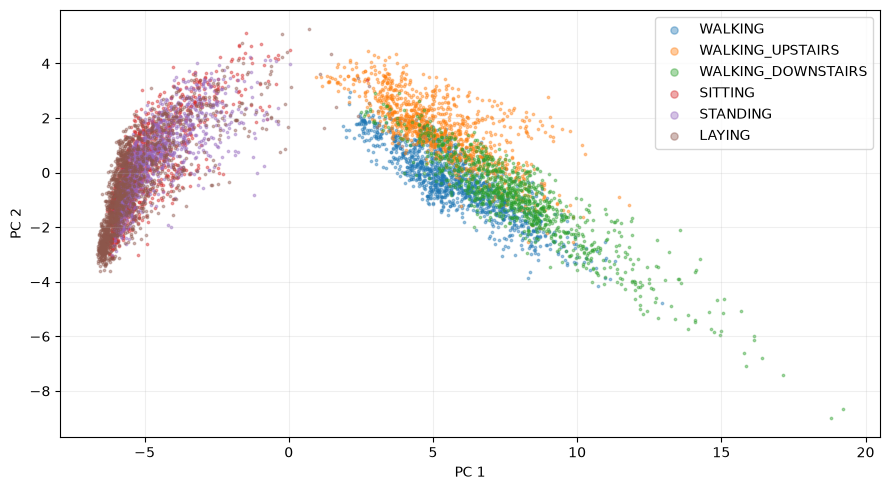

In [3]:
from sklearn.decomposition import PCA

engineered = np.loadtxt(HAR / 'train/X_train.txt', dtype=np.float32)
har_labels = np.loadtxt(HAR / 'train/y_train.txt', dtype=np.int64) - 1
pca = PCA(n_components=2, random_state=SEED)
projection = pca.fit_transform(engineered)
LABELS = ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS', 'SITTING', 'STANDING', 'LAYING']
plt.figure(figsize=(9, 5))
for label, name in enumerate(LABELS):
    mask = har_labels == label
    plt.scatter(*projection[mask].T, s=3, alpha=0.4, label=name)
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.legend(markerscale=3)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Загрузка исходных сигналов

In [4]:
SIGNALS = ['body_acc_x', 'body_acc_y', 'body_acc_z', 'body_gyro_x',
           'body_gyro_y', 'body_gyro_z', 'total_acc_x', 'total_acc_y', 'total_acc_z']

def load_har(part):
    x = np.stack([np.loadtxt(HAR / part / 'Inertial Signals' / f'{s}_{part}.txt',
                             dtype=np.float32) for s in SIGNALS], axis=1)
    y = np.loadtxt(HAR / part / f'y_{part}.txt', dtype=np.int64) - 1
    subjects = np.loadtxt(HAR / part / f'subject_{part}.txt', dtype=np.int64)
    return x, y, subjects

har_x, har_y, subjects = load_har('train')
har_test_x, har_test_y, test_subjects = load_har('test')
from sklearn.model_selection import GroupShuffleSplit
tr_idx, va_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
                      .split(har_x, har_y, groups=subjects))
assert not set(subjects[tr_idx]) & set(subjects[va_idx])
assert not set(subjects) & set(test_subjects)
channel_mean = har_x[tr_idx].mean(axis=(0, 2), keepdims=True)
channel_std = har_x[tr_idx].std(axis=(0, 2), keepdims=True).clip(min=1e-6)
har_x = torch.from_numpy((har_x - channel_mean) / channel_std)
har_test_x = torch.from_numpy((har_test_x - channel_mean) / channel_std)
har_y, har_test_y = torch.from_numpy(har_y), torch.from_numpy(har_test_y)
print('Train / validation / test:', len(tr_idx), len(va_idx), len(har_test_y))
print('Validation subjects:', sorted(set(subjects[va_idx])))

Train / validation / test: 5551 1801 2947
Validation subjects: [np.int64(1), np.int64(3), np.int64(15), np.int64(25), np.int64(27)]


In [5]:
print('Форма сигналов:', tuple(har_x.shape), '| классы:', torch.unique(har_y).tolist())

Форма сигналов: (7352, 9, 128) | классы: [0, 1, 2, 3, 4, 5]


### Обучение классификатора

Эпоха выбирается по validation loss, после этого один раз считается accuracy на test.

В сети три слоя Conv1d с BatchNorm и ReLU, после первых двух стоит MaxPool. Дальше AdaptiveAvgPool до 8 отсчётов и полносвязный слой на 6 классов. Также используются Dropout и weight decay. Каналы нормируются по статистикам train.

ActivityNet(
  (features): Sequential(
    (0): Conv1d(9, 32, kernel_size=(7,), stride=(1,), padding=(3,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool1d(output_size=8)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=512, out_features=64, bias=True)
    (3): ReLU()
    (

Эпоха   1: train acc=0.9442, val acc=0.9833, train loss=0.1631, val loss=0.1209


Эпоха   5: train acc=0.9523, val acc=0.9684, train loss=0.1164, val loss=0.1350


Эпоха  10: train acc=0.9472, val acc=0.9728, train loss=0.1001, val loss=0.1132


Эпоха  15: train acc=0.9589, val acc=0.9650, train loss=0.0849, val loss=0.1291


Эпоха  20: train acc=0.9645, val acc=0.9528, train loss=0.0748, val loss=0.1750


... (5 outputs left out)

Эпоха  50: train acc=0.9748, val acc=0.9611, train loss=0.0520, val loss=0.2109


Эпоха  55: train acc=0.9741, val acc=0.9611, train loss=0.0529, val loss=0.1945


Эпоха  60: train acc=0.9739, val acc=0.9545, train loss=0.0512, val loss=0.2211


Выбранная эпоха: 4 | официальный test: {'loss': 0.23872241449631146, 'accuracy': 0.9077027485578555}


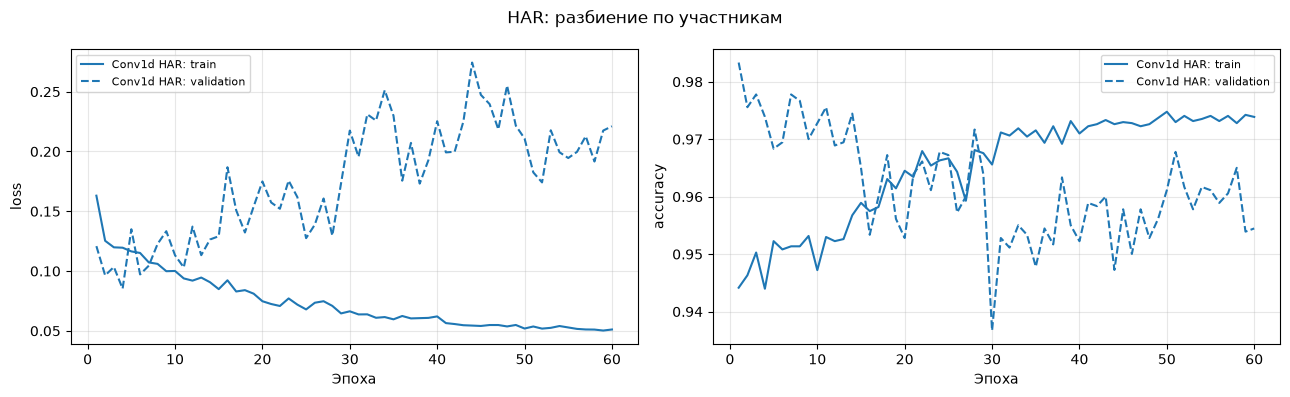

                    precision    recall  f1-score   support

           WALKING     1.0000    0.9073    0.9514       496
  WALKING_UPSTAIRS     0.9978    0.9490    0.9728       471
WALKING_DOWNSTAIRS     0.8571    1.0000    0.9231       420
           SITTING     0.8368    0.7312    0.7804       491
          STANDING     0.7817    0.8684    0.8228       532
            LAYING     0.9963    1.0000    0.9981       537

          accuracy                         0.9077      2947
         macro avg     0.9116    0.9093    0.9081      2947
      weighted avg     0.9120    0.9077    0.9076      2947



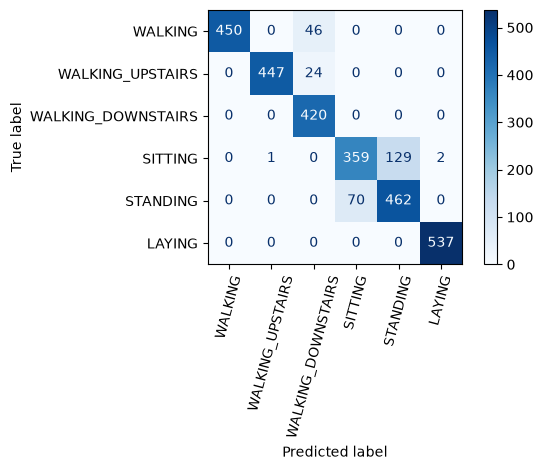

In [6]:
class ActivityNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(9, 32, 7, padding=3), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, 5, padding=2), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, 64, 3, padding=1), nn.BatchNorm1d(64), nn.ReLU(),
            nn.AdaptiveAvgPool1d(8))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(512, 64),
                                        nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 6))

    def forward(self, x):
        return self.classifier(self.features(x))

set_seed()
activity_model = ActivityNet().to(device)
print(activity_model)
har_history, har_epoch = fit(
    activity_model, loader(har_x[tr_idx], har_y[tr_idx], batch_size=128, shuffle=True),
    loader(har_x[tr_idx], har_y[tr_idx]), loader(har_x[va_idx], har_y[va_idx]),
    epochs=60, lr=1e-3, weight_decay=1e-3)
har_test = evaluate(activity_model, loader(har_test_x, har_test_y))
print('Выбранная эпоха:', har_epoch, '| официальный test:', har_test)
assert har_test['accuracy'] >= 0.86
plot_histories({'Conv1d HAR': har_history}, 'HAR: разбиение по участникам')
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
activity_model.to(device).eval()
with torch.no_grad():
    predicted = torch.cat([activity_model(x.to(device)).argmax(1).cpu()
                           for x, _ in loader(har_test_x, har_test_y)])
print(classification_report(har_test_y, predicted, target_names=LABELS, digits=4))
ConfusionMatrixDisplay.from_predictions(har_test_y, predicted, display_labels=LABELS,
                                        xticks_rotation=75, cmap='Blues')
plt.tight_layout()
plt.show()

### Part 5. Dogs classification

В архиве 7 166 размеченных картинок 50 пород и 1 503 тестовые картинки без меток. 20% размеченных отложены на validation, пропорции классов сохранены.

Используется fine-tuning в простом виде: EfficientNet-B0 с замороженными весами выдаёт признаки, и поверх них обучается только линейный слой на 50 классов. Признаки считаются для картинки и её зеркального отражения и усредняются. Они сохраняются в кэш, потому что на CPU их подсчёт занимает много времени. Эпоха выбирается по validation loss, потом слой обучается заново на всех размеченных картинках и делает предсказания для test.

Train / validation / hidden test: 5732 1434 1503


Эпоха   1: train acc=0.9445, val acc=0.9386, train loss=0.2676, val loss=0.2843


Эпоха   5: train acc=0.9902, val acc=0.9589, train loss=0.0645, val loss=0.1415


Эпоха  10: train acc=0.9979, val acc=0.9603, train loss=0.0289, val loss=0.1320


Эпоха  15: train acc=0.9993, val acc=0.9561, train loss=0.0173, val loss=0.1272


Эпоха  20: train acc=0.9995, val acc=0.9582, train loss=0.0128, val loss=0.1272


... (2 outputs left out)

Эпоха  35: train acc=0.9998, val acc=0.9575, train loss=0.0078, val loss=0.1266


Эпоха  40: train acc=0.9998, val acc=0.9568, train loss=0.0074, val loss=0.1269


Эпоха  45: train acc=0.9998, val acc=0.9575, train loss=0.0072, val loss=0.1268


Выбранная эпоха: 22
Validation: {'loss': 0.12514641494431755, 'accuracy': 0.9574616457461645}


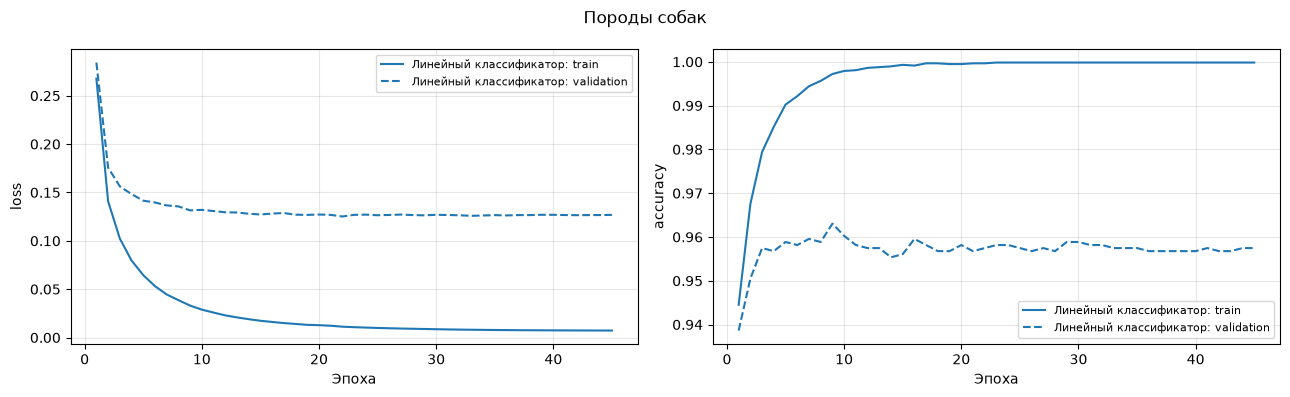

Создан dogs_predictions.csv: 1503 строк; заголовок отсутствует.


,filename,class
0,0.jpeg,42
1,1.jpeg,3
2,2.jpeg,14
3,3.jpeg,14
4,4.jpeg,39


In [7]:
import torchvision
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from torchvision.datasets import ImageFolder
from PIL import Image
from sklearn.model_selection import train_test_split

DOGS = DATA / 'dogs' / 'data'
if not DOGS.exists():
    download_archive('https://www.dropbox.com/s/vgqpz2f1lolxmlv/data.zip?dl=1',
                     DATA / 'dogs.zip', DATA / 'dogs')
weights = EfficientNet_B0_Weights.DEFAULT
preprocess = weights.transforms()
torch.hub.set_dir(str(DATA / 'torch_hub'))
backbone = efficientnet_b0(weights=weights).to(device).eval()
backbone.classifier = nn.Identity()
for parameter in backbone.parameters():
    parameter.requires_grad_(False)
dogs_train = ImageFolder(DOGS / 'train', transform=preprocess)
class_names = dogs_train.classes
assert len(class_names) == 50

test_paths = sorted((DOGS / 'test').glob('*.jpeg'), key=lambda p: int(p.stem))

class DogImages(torch.utils.data.Dataset):
    def __init__(self, paths):
        self.paths = paths

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            return preprocess(image.convert('RGB'))

@torch.no_grad()
def extract_features(paths, cache_name):
    cache = ARTIFACTS / cache_name
    if cache.exists():
        features = torch.load(cache, weights_only=True)
        assert features.shape == (len(paths), 1280)
        return features
    batches = DataLoader(DogImages(paths), batch_size=32, num_workers=0, shuffle=False)
    features = []
    for i, images in enumerate(batches):
        images = images.to(device)
        values = (backbone(images) + backbone(images.flip(-1))) / 2
        features.append(values.cpu())
        if i % 25 == 0:
            print(f'Извлечение {cache_name}: {min((i + 1) * 32, len(paths))}/{len(paths)}', flush=True)
    features = torch.cat(features)
    torch.save(features, cache)
    return features

dog_features = extract_features([Path(p) for p, _ in dogs_train.samples], 'dogs_train_features.pt')
dog_test_features = extract_features(test_paths, 'dogs_test_features.pt')
dog_labels = torch.tensor(dogs_train.targets, dtype=torch.long)
dog_tr, dog_va = train_test_split(np.arange(len(dog_labels)), test_size=0.2,
                                 stratify=dog_labels.numpy(), random_state=SEED)
feature_mean = dog_features[dog_tr].mean(0)
feature_std = dog_features[dog_tr].std(0).clamp_min(0.05)
normalized_features = (dog_features - feature_mean) / feature_std
print('Train / validation / hidden test:', len(dog_tr), len(dog_va), len(test_paths))

class DogHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(nn.Dropout(0.3), nn.Linear(1280, 50))

    def forward(self, x):
        return self.layers(x)

set_seed()
head = DogHead().to(device)
dog_history, dog_epoch = fit(
    head, loader(normalized_features[dog_tr], dog_labels[dog_tr], shuffle=True),
    loader(normalized_features[dog_tr], dog_labels[dog_tr]),
    loader(normalized_features[dog_va], dog_labels[dog_va]),
    epochs=45, lr=1e-3, weight_decay=0.01)
dog_validation = evaluate(head, loader(normalized_features[dog_va], dog_labels[dog_va]))
print('Выбранная эпоха:', dog_epoch)
print('Validation:', dog_validation)
plot_histories({'Линейный классификатор': dog_history}, 'Породы собак')

# финальный классификатор обучается на всех размеченных картинках, число эпох берётся с validation
full_mean = dog_features.mean(0)
full_std = dog_features.std(0).clamp_min(0.05)
full_x = (dog_features - full_mean) / full_std
set_seed()
final_head = DogHead().to(device)
optimizer = torch.optim.AdamW(final_head.parameters(), lr=1e-3, weight_decay=0.01)
# расписание lr такое же, как при подборе (на 45 эпох)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, 45, eta_min=5e-5)
full_batches = loader(full_x, dog_labels, shuffle=True)
for epoch in range(dog_epoch):
    final_head.train()
    for x, y in full_batches:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = nn.functional.cross_entropy(final_head(x), y)
        loss.backward()
        optimizer.step()
    scheduler.step()
final_head.eval()
with torch.no_grad():
    test_logits = final_head(((dog_test_features - full_mean) / full_std).to(device))
test_labels = [class_names[i] for i in test_logits.argmax(1).cpu().tolist()]
submission = pd.DataFrame({'filename': [p.name for p in test_paths], 'class': test_labels})
assert len(submission) == 1503 and submission.filename.is_unique
assert set(submission['class']) <= set(class_names)
submission.to_csv('dogs_predictions.csv', index=False, header=False)
print('Создан dogs_predictions.csv:', len(submission), 'строк; заголовок отсутствует.')
display(submission.head())

### Выводы

HAR: выбрана 4-я эпоха, accuracy на test 0.9077. Это выше порога 89%, но ниже 91%. Больше всего ошибок между SITTING и STANDING: 129 раз сидение принято за стояние и 70 раз наоборот, это 199 из 272 ошибок.

Собаки: линейный слой обучался на 5 732 картинках, validation 1 434 картинки. Выбрана 22-я эпоха, validation accuracy 0.9575. Потом слой обучен на всех 7 166 картинках те же 22 эпохи.

Предсказания лежат в dogs_predictions.csv: 1 503 строки вида имя_картинки,класс без заголовка. Номер класса берётся из названия папки в train. Меток для test нет, поэтому 0.9575 - это точность на своей validation, а точность на test считается при проверке.